In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv('../data/creditcard.csv')

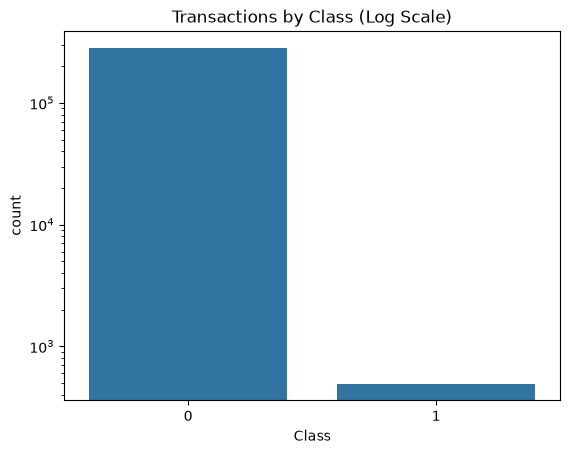

In [91]:
sns.countplot(x="Class", data=df)
plt.yscale('log')
plt.title("Transactions by Class (Log Scale)")
plt.savefig("../figures/Class_Balance.png",dpi=150,bbox_inches='tight')
plt.show()

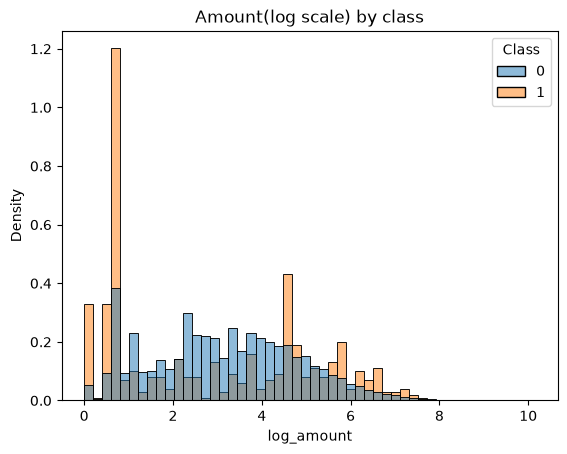

In [92]:
df["log_amount"]=np.log1p(df["Amount"])
sns.histplot(x="log_amount",data=df,hue="Class",stat="density",common_norm=False,bins=50)
plt.title("Amount(log scale) by class")
plt.savefig("../figures/Amount_by_class.png",dpi=150,bbox_inches='tight')
plt.show()

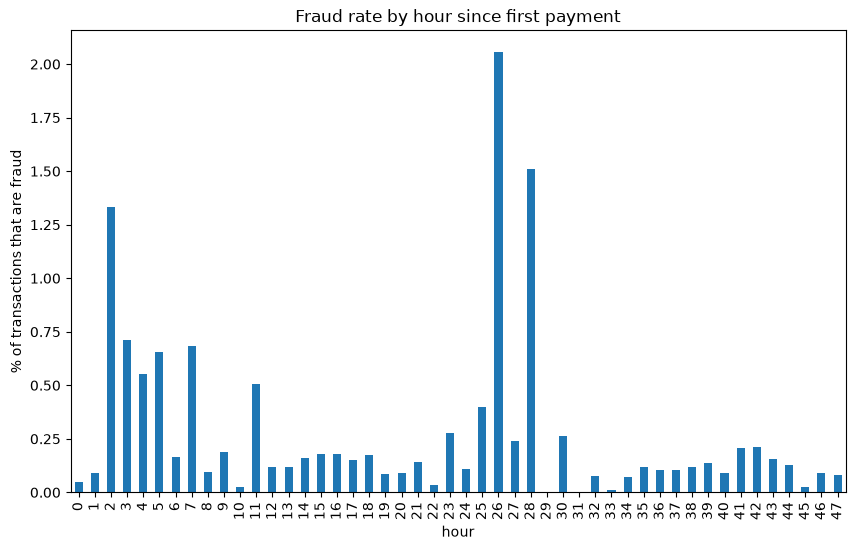

In [93]:
df["hour"]=(df["Time"]//3600).astype(int)
by_hour=df.groupby("hour")["Class"].agg(fraud="sum",total="count")
by_hour["fraud_rate_%"]=100*by_hour["fraud"]/by_hour["total"]
by_hour["fraud_rate_%"].plot(kind="bar",figsize=(10,6))
plt.title("Fraud rate by hour since first payment")
plt.ylabel("% of transactions that are fraud")
plt.savefig("../figures/fraud_by_hour.png",dpi=150,bbox_inches="tight")
plt.show()

In [94]:
v_cols=[f"V{i}"for  i in range(1,29)]
fraud_mean=df[df["Class"]==1][v_cols].mean()
normal_mean=df[df["Class"]==0][v_cols].mean()
separation=((fraud_mean-normal_mean)/df[v_cols].std()).abs().sort_values(ascending=False)
separation.head(10)

V17    7.861863
V14    7.285436
V12    6.275236
V10    5.222673
V16    4.732777
V3     4.646614
V7     4.509253
V11    3.729500
V4     3.213497
V18    2.684633
dtype: float64

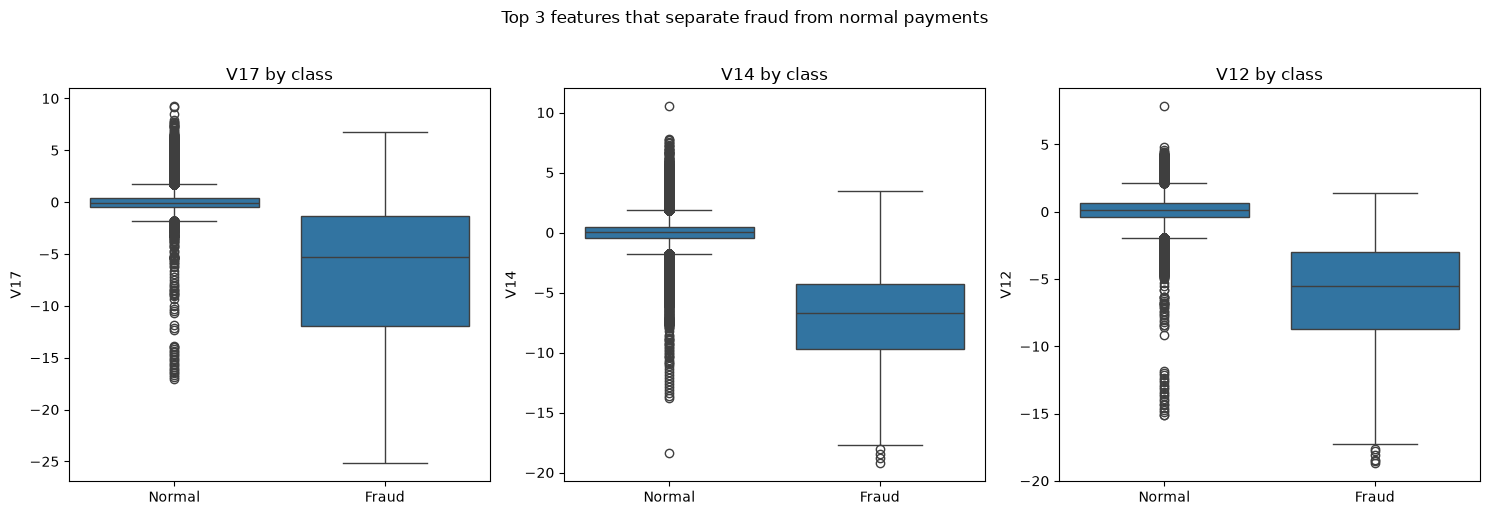

In [95]:
top_3_features = separation.head(3).index
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, feature in enumerate(top_3_features):
    sns.boxplot(data=df, x="Class", y=feature, ax=axes[i])
    axes[i].set_title(f"{feature} by class")
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(["Normal", "Fraud"])
    axes[i].set_xlabel("")
plt.suptitle("Top 3 features that separate fraud from normal payments", y=1.02)
plt.tight_layout()
plt.savefig("../figures/top3_v_features.png", dpi=150, bbox_inches="tight")
plt.show()

In [96]:
print("Before:",len(df))
df=df.drop_duplicates().reset_index(drop=True)
print("After:",len(df))
df=df.sort_values("Time").reset_index(drop=True)
feature_cols=[f"V{i}"for i in range(1,29)]+["log_amount"]
x=df[feature_cols]
y=df["Class"]
cut=int(len(df)*0.8)
x_train,x_test=x.iloc[:cut],x.iloc[cut:]
y_train,y_test=y.iloc[:cut],y.iloc[cut:]
print("Train:",len(x_train),"Fraud:",y_train.sum())
print("Test:",len(x_test),"Fraud:",y_test.sum())

Before: 284807
After: 283726
Train: 226980 Fraud: 399
Test: 56746 Fraud: 74


In [97]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score
base=DummyClassifier(strategy="most_frequent").fit(x_train,y_train)
pred=base.predict(x_test)
print("Accuracy:",round(accuracy_score(y_test,pred),4))
print("Recall:",recall_score(y_test,pred))
print("Precision:",precision_score(y_test,pred,zero_division=0))
print("Fraud rate in test:",round(y_test.mean(),4))

Accuracy: 0.9987
Recall: 0.0
Precision: 0.0
Fraud rate in test: 0.0013


In [98]:
cut2 = int(len(x_train) * 0.8)
x_fit, x_val = x_train.iloc[:cut2], x_train.iloc[cut2:]
y_fit, y_val = y_train.iloc[:cut2], y_train.iloc[cut2:]

print("Fit:", len(x_fit), "rows,", y_fit.sum(), "fraud")
print("Val:", len(x_val), "rows,", y_val.sum(), "fraud")

Fit: 181584 rows, 347 fraud
Val: 45396 rows, 52 fraud


In [99]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
lr=Pipeline([
    ("scale",StandardScaler()),
    ("clf",LogisticRegression(max_iter=1000,class_weight="balanced"))
])
lr.fit(x_fit,y_fit)
lr_scores=lr.predict_proba(x_val)[:,1]
neg,pos=(y_fit==0).sum(),(y_val==1).sum()
xgb= XGBClassifier(
    n_estimators=300, max_depth=4,learning_depth=0.1,
    scale_pos_weight=neg/pos,
    eval_metrics="aucpr",random_state=42,n_jobs=-1  
)
xgb.fit(x_fit,y_fit)
xgb_scores=xgb.predict_proba(x_val)[:,1]


In [100]:
from sklearn.metrics import average_precision_score,roc_auc_score,precision_score,recall_score
for name, scores in [("Logistic Regression",lr_scores),("XGBoost",xgb_scores)]:
    pred=(scores>=0.5).astype(int)
    print(name)
    print("PR-AUC (average_precision):",round(average_precision_score(y_val,scores),3))
    print("ROC-AUC:",round(roc_auc_score(y_val,scores),3))
    print("Precision_score:",round(precision_score(y_val,pred,zero_division=0),3))
    print("Recall score:",round(recall_score(y_val,pred),3))
print("A useless model's PR-AUC:",round(y_val.mean(),4))


Logistic Regression
PR-AUC (average_precision): 0.741
ROC-AUC: 0.97
Precision_score: 0.032
Recall score: 0.885
XGBoost
PR-AUC (average_precision): 0.798
ROC-AUC: 0.98
Precision_score: 0.867
Recall score: 0.75
A useless model's PR-AUC: 0.0011


In [101]:
amt_val = df.loc[x_val.index, "Amount"].values
y_v = y_val.values
def cost_table(scores, review_cost=5):
    rows = []
    for t in np.arange(0.05, 1.0, 0.05):
        flagged = scores >= t
        missed = (~flagged) & (y_v == 1)
        rows.append({
            "threshold": round(t, 2),
            "alerts": int(flagged.sum()),
            "missed_fraud": int(missed.sum()),
            "fraud_loss": round(amt_val[missed].sum(), 0),
            "review_cost": review_cost * int(flagged.sum()),
        })
    out = pd.DataFrame(rows)
    out["total_cost"] = out["fraud_loss"] + out["review_cost"]
    return out

ct = cost_table(xgb_scores, review_cost=5)
print(ct.sort_values("total_cost").head(5))

    threshold  alerts  missed_fraud  fraud_loss  review_cost  total_cost
15       0.80      41            13      2349.0          205      2554.0
18       0.95      41            13      2349.0          205      2554.0
17       0.90      41            13      2349.0          205      2554.0
16       0.85      41            13      2349.0          205      2554.0
14       0.75      42            13      2349.0          210      2559.0


In [102]:
from sklearn.metrics import precision_recall_curve
prec, rec, thr = precision_recall_curve(y_val, xgb_scores)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
best = f1.argmax()
print("Threshold:", round(thr[best], 3),
      "| precision:", round(prec[best], 3),
      "| recall:", round(rec[best], 3),
      "| F1:", round(f1[best], 3))

Threshold: 0.965 | precision: 1.0 | recall: 0.75 | F1: 0.857
